In [ ]:
# Telco Customer Churn Prediction - MLOps Project
# Lab 1-4: ML Project Initialization, Baseline Model,
# Git Version Control, and MLflow Experiment Tracking


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv(r"C:\Users\lksch\OneDrive\Documents\OneDrive\Desktop\churn_prediction_339\data\raw\churn.csv")

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (7044, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
print("Column Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data Types:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

Dataset Information:
<class 'pandas.DataFrame'

In [4]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

Missing Values in Each Column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [5]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [6]:
print("Blank values in TotalCharges:")
print((df["TotalCharges"].astype(str).str.strip() == "").sum())

Blank values in TotalCharges:
11


In [7]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Missing values in TotalCharges after conversion:")
print(df["TotalCharges"].isnull().sum())

Missing values in TotalCharges after conversion:
11


In [8]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

print("Missing values after filling:")
print(df["TotalCharges"].isnull().sum())

Missing values after filling:
0


In [9]:
df = df.drop_duplicates()

print("Dataset Shape after removing duplicates:", df.shape)

Dataset Shape after removing duplicates: (7044, 21)


In [10]:
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

print("Churn values after conversion:")
print(df["Churn"].value_counts())

Churn values after conversion:
Churn
0    5175
1    1869
Name: count, dtype: int64


In [11]:
print("Final Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nFirst 5 Rows:")
df.head()

Final Dataset Shape: (7044, 21)

Missing Values:
0

First 5 Rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [12]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (7044, 20)
Target Shape: (7044,)


In [13]:
X = X.drop(columns=["customerID"])

print("Features Shape after removing customerID:", X.shape)
print("\nRemaining Columns:")
print(X.columns.tolist())

Features Shape after removing customerID: (7044, 19)

Remaining Columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']


In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Set Shape:", X_train.shape)
print("Testing Set Shape:", X_test.shape)

Training Set Shape: (5635, 19)
Testing Set Shape: (1409, 19)


In [15]:
numerical_features = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object"]).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


C:\Users\lksch\AppData\Local\Temp\ipykernel_12080\2669841590.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(include=["object"]).columns.tolist()


In [16]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder

scaler = StandardScaler()
ohe = OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore")

X_train_num = scaler.fit_transform(X_train[numerical_features])
X_test_num = scaler.transform(X_test[numerical_features])

X_train_cat = ohe.fit_transform(X_train[categorical_features])
X_test_cat = ohe.transform(X_test[categorical_features])

X_train_final = np.hstack([X_train_num, X_train_cat])
X_test_final = np.hstack([X_test_num, X_test_cat])

print("Final Training Shape:", X_train_final.shape)
print("Final Testing Shape:", X_test_final.shape)

Final Training Shape: (5635, 30)
Final Testing Shape: (1409, 30)


In [17]:
import os
import joblib

os.makedirs("../data/processed", exist_ok=True)
os.makedirs("../models", exist_ok=True)

np.save("../data/processed/X_train_final.npy", X_train_final)
np.save("../data/processed/X_test_final.npy", X_test_final)
np.save("../data/processed/y_train.npy", y_train.to_numpy())
np.save("../data/processed/y_test.npy", y_test.to_numpy())

joblib.dump(scaler, "../models/scaler.pkl")
joblib.dump(ohe, "../models/ohe.pkl")

print("Processed data and preprocessing objects saved successfully.")

Processed data and preprocessing objects saved successfully.


In [18]:
import json

metadata = {
    "dataset_name": "Telco Customer Churn",
    "train_shape": list(X_train_final.shape),
    "test_shape": list(X_test_final.shape),
    "numerical_features": numerical_features,
    "categorical_features": categorical_features
}

with open("../data/processed/dataset_metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("dataset_metadata.json saved successfully.")

dataset_metadata.json saved successfully.


In [19]:
print("Saved files:")

print("\nProcessed Data:")
print(os.listdir("../data/processed"))

print("\nModels:")
print(os.listdir("../models"))

Saved files:

Processed Data:
['dataset_metadata.json', 'X_test_final.npy', 'X_train_final.npy', 'y_test.npy', 'y_train.npy']

Models:
['ohe.pkl', 'scaler.pkl']


In [20]:
from sklearn.ensemble import RandomForestClassifier

X_train_final = np.load("../data/processed/X_train_final.npy")
X_test_final = np.load("../data/processed/X_test_final.npy")
y_train = np.load("../data/processed/y_train.npy")
y_test = np.load("../data/processed/y_test.npy")

print("Training Data Shape:", X_train_final.shape)
print("Testing Data Shape:", X_test_final.shape)

Training Data Shape: (5635, 30)
Testing Data Shape: (1409, 30)


In [21]:
model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train_final, y_train)

print("Random Forest baseline model trained successfully.")

Random Forest baseline model trained successfully.


In [22]:
joblib.dump(model, "../models/random_forest_baseline.pkl")

print("Baseline model saved successfully.")

Baseline model saved successfully.


In [23]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred = model.predict(X_test_final)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Baseline Random Forest Results")
print("------------------------------")
print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

Baseline Random Forest Results
------------------------------
Accuracy : 0.7558552164655784
Precision: 0.5275735294117647
Recall   : 0.767379679144385
F1 Score : 0.6252723311546841


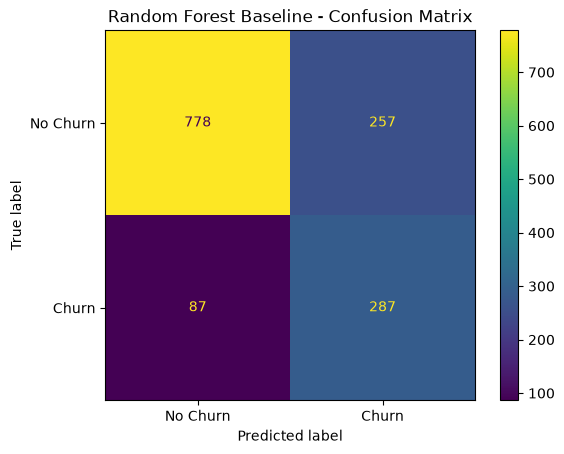

In [24]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot()
plt.title("Random Forest Baseline - Confusion Matrix")
plt.show()

In [25]:
metrics = {
    "accuracy": accuracy,
    "precision": precision,
    "recall": recall,
    "f1_score": f1
}

print("Evaluation metrics calculated successfully.")
print(metrics)

Evaluation metrics calculated successfully.
{'accuracy': 0.7558552164655784, 'precision': 0.5275735294117647, 'recall': 0.767379679144385, 'f1_score': 0.6252723311546841}


In [26]:
from sklearn.metrics import roc_auc_score, roc_curve

y_prob = model.predict_proba(X_test_final)[:, 1]

roc_auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC Score:", roc_auc)

ROC-AUC Score: 0.8433490919424423


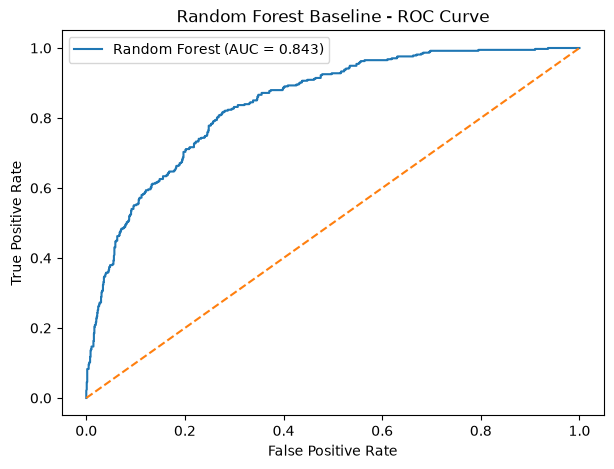

In [27]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Random Forest (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest Baseline - ROC Curve")
plt.legend()
plt.show()

In [28]:

original_df = pd.read_csv(r"C:\Users\lksch\OneDrive\Documents\OneDrive\Desktop\churn_prediction_339\data\raw\churn.csv")


_, test_df = train_test_split(
    original_df,
    test_size=0.2,
    random_state=42,
    stratify=original_df["Churn"]
)

test_df = test_df.reset_index(drop=True)


test_df["Actual_Churn"] = y_test
test_df["Predicted_Churn"] = y_pred


false_negatives = test_df[
    (test_df["Actual_Churn"] == 1) &
    (test_df["Predicted_Churn"] == 0)
]


false_positives = test_df[
    (test_df["Actual_Churn"] == 0) &
    (test_df["Predicted_Churn"] == 1)
]

false_negatives.to_csv("../outputs/false_negatives.csv", index=False)
false_positives.to_csv("../outputs/false_positives.csv", index=False)

print("False Negatives:", len(false_negatives))
print("False Positives:", len(false_positives))
print("Error analysis files saved successfully.")

False Negatives: 87
False Positives: 257
Error analysis files saved successfully.


In [29]:
print("False Negatives:")
display(false_negatives.head())

print("\nFalse Positives:")
display(false_positives.head())

False Negatives:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Actual_Churn,Predicted_Churn
13,9820-RMCQV,Female,0,No,No,11,Yes,No,DSL,Yes,...,No,No,Month-to-month,No,Credit card (automatic),48.55,501,Yes,1,0
29,4190-MFLUW,Female,0,Yes,Yes,10,Yes,No,DSL,No,...,No,No,Month-to-month,No,Credit card (automatic),55.20,528.35,Yes,1,0
38,1205-WNWPJ,Female,0,No,No,7,Yes,No,DSL,No,...,Yes,No,Month-to-month,Yes,Mailed check,59.50,415.95,Yes,1,0
39,4701-MLJPN,Male,0,No,No,31,Yes,No,DSL,No,...,No,No,Month-to-month,Yes,Electronic check,55.25,1715.65,Yes,1,0
51,1493-AMTIE,Male,0,No,No,1,Yes,No,No,No internet service,...,No internet service,No internet service,Month-to-month,Yes,Bank transfer (automatic),20.20,20.2,Yes,1,0



False Positives:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Actual_Churn,Predicted_Churn
1,2754-SDJRD,Female,1,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,Yes,Month-to-month,Yes,Credit card (automatic),100.15,908.55,No,0,1
3,0365-GXEZS,Male,0,Yes,No,18,Yes,No,Fiber optic,No,...,No,No,Month-to-month,No,Electronic check,78.20,1468.75,No,0,1
5,4686-UXDML,Female,0,No,No,21,Yes,Yes,Fiber optic,No,...,Yes,Yes,Month-to-month,Yes,Credit card (automatic),99.85,1992.55,No,0,1
6,2227-JRSJX,Female,0,No,No,21,Yes,No,Fiber optic,No,...,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),99.15,1956.4,No,0,1
17,1379-FRVEB,Male,0,No,Yes,15,Yes,Yes,Fiber optic,No,...,Yes,No,Month-to-month,Yes,Electronic check,91.00,1430.05,No,0,1


In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        class_weight="balanced"
    )
}

results = []

for name, clf in models.items():
    clf.fit(X_train_final, y_train)
    predictions = clf.predict(X_test_final)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions)
    })

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.806246,0.657321,0.564171,0.607194
1,Decision Tree,0.733854,0.498701,0.513369,0.505929
2,Random Forest,0.755855,0.527574,0.767380,0.625272


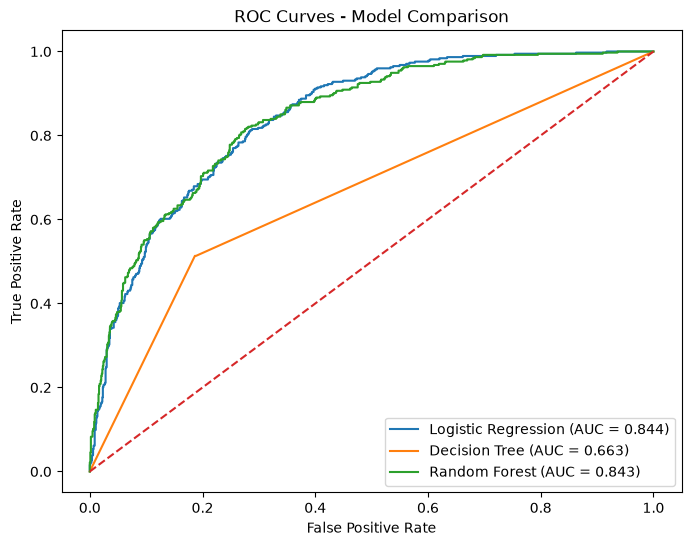

In [31]:
plt.figure(figsize=(8, 6))

for name, clf in models.items():
    probabilities = clf.predict_proba(X_test_final)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc_score = roc_auc_score(y_test, probabilities)

    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_score:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Model Comparison")
plt.legend()
plt.show()

In [32]:
results_df.to_csv("../outputs/model_comparison.csv", index=False)

print("Model comparison results saved successfully.")

Model comparison results saved successfully.


In [34]:
print("========== PROJECT VERIFICATION ==========")

print("\nDataset:")
print("Original Shape:", df.shape)

print("\nProcessed Data:")
print("X_train:", X_train_final.shape)
print("X_test :", X_test_final.shape)

print("\nBaseline Model:")
print("Random Forest trained and saved successfully.")

print("\nModel Comparison:")
print(results_df)



========== PROJECT VERIFICATION ==========

Dataset:
Original Shape: (7044, 21)

Processed Data:
X_train: (5635, 30)
X_test : (1409, 30)

Baseline Model:
Random Forest trained and saved successfully.

Model Comparison:
                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.806246   0.657321  0.564171  0.607194
1        Decision Tree  0.733854   0.498701  0.513369  0.505929
2        Random Forest  0.755855   0.527574  0.767380  0.625272
